# Customer Churn Storyboard (Guided EDA)
**GetIntern.in | Week 4 Milestone Project | Phase 1 Capstone: Exploratory Data Analysis**

This notebook tells a data story about customer attrition in a telecom company using **Pandas, Seaborn and Matplotlib**.

**Business questions**
1. **Overall attrition baseline:** what is the churn rate across all customer accounts?
2. **Contract impact:** how much does contract type (Month-to-Month vs One-Year/Two-Year) influence churn?
3. **Billing & payment factors:** does payment method show a visible link with churn?

**Dataset:** Telco Customer Churn (Kaggle), 7,043 customers and 21 columns.

## Setup
### Step 1: Import libraries
Pandas and NumPy handle the data. Matplotlib and Seaborn create the charts.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

### Step 2: Load the dataset
Load `WA_Fn-UseC_-Telco-Customer-Churn.csv`. Each row is one customer, with columns for services, contract, billing, payment method and whether the customer churned.

In [ ]:
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
print("Shape:", df.shape)
df.head()

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### Step 3: Inspect the data
Check data types, duplicates, missing values and the values in the key columns (`Churn`, `Contract`, `PaymentMethod`). There are 7,043 rows, no duplicates and no missing values, but `TotalCharges` is stored as text, so it needs cleaning.

In [ ]:
df.info()
print("\nDuplicates:", df.duplicated().sum())
print("\nNulls:\n", df.isnull().sum()[lambda s: s > 0])
print("\nChurn values:\n", df["Churn"].value_counts())
print("\nContract values:\n", df["Contract"].value_counts())
print("\nPaymentMethod values:\n", df["PaymentMethod"].value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


### Step 4: Clean the data
- Remove duplicate rows (none were found).
- Convert `TotalCharges` to numbers. The 11 blank values belong to new customers with tenure 0 who have not been billed yet, so they are filled with 0. This keeps all 7,043 customer accounts in the analysis.
- Strip extra spaces from text columns.
- Add a numeric `churn_flag` (1 = churned, 0 = stayed) so churn rates can be calculated with a simple average.

In [ ]:
df = df.drop_duplicates()

# TotalCharges is text with blank values (new customers with tenure 0)
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Blank TotalCharges:", df["TotalCharges"].isna().sum())
df["TotalCharges"] = df["TotalCharges"].fillna(0)   # not billed yet

# Clean text and add a numeric churn flag (1 = churned)
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()
df["churn_flag"] = (df["Churn"] == "Yes").astype(int)

print("Final shape:", df.shape, "| Nulls:", df.isnull().sum().sum())

Blank TotalCharges: 11
Final shape: (7043, 22) | Nulls: 0


## Business Question 1: Overall Attrition Baseline
### Step 5: Calculate the churn rate
Count how many customers churned and calculate the overall churn rate. This is the baseline for every comparison below.

In [ ]:
churn_counts = df["Churn"].value_counts()
churn_rate = df["churn_flag"].mean() * 100
print(churn_counts)
print(f"\nOverall churn rate: {churn_rate:.2f}%")

Churn
No     5174
Yes    1869
Name: count, dtype: int64

Overall churn rate: 26.54%


### Step 6: Chart 1, Customer churn baseline
A bar chart of customers who stayed versus customers who churned, with counts and percentages.

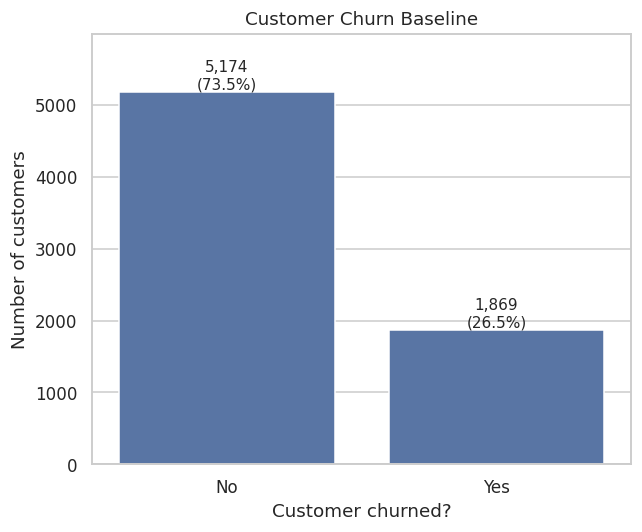

In [ ]:
fig, ax = plt.subplots(figsize=(6, 5))
sns.countplot(data=df, x="Churn", order=["No", "Yes"], color="#4C72B0", ax=ax)

total = len(df)
for p in ax.patches:
    ax.annotate(f"{p.get_height():,.0f}\n({p.get_height() / total * 100:.1f}%)",
                (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom", fontsize=10)

ax.set_title("Customer Churn Baseline")
ax.set_xlabel("Customer churned?")
ax.set_ylabel("Number of customers")
ax.set_ylim(0, total * 0.85)
plt.tight_layout()
plt.savefig("churn_baseline.png", dpi=150, bbox_inches="tight")
plt.show()

- **What this shows:** Overall churn is **26.5%**: 1,869 of 7,043 customers left, while 5,174 stayed.
- **Business meaning:** About 1 in 4 customers churns, so 26.5% is the baseline that every segment below is compared with.

## Business Question 2: Contract Impact
### Step 7: Churn rate by contract type
Group customers by contract (Month-to-month, One year, Two year) and calculate the number of customers, number churned and churn rate for each.

In [ ]:
contract_churn = df.groupby("Contract")["churn_flag"].agg(
    customers="count", churned="sum", churn_rate="mean").reset_index()
contract_churn["churn_rate"] = (contract_churn["churn_rate"] * 100).round(2)
contract_churn = contract_churn.sort_values("churn_rate", ascending=False)
contract_churn

,Contract,customers,churned,churn_rate
0,Month-to-month,3875,1655,42.71
1,One year,1473,166,11.27
2,Two year,1695,48,2.83


### Step 8: Chart 2, Churn rate by contract type
A bar chart of churn rate for each contract type. The red dashed line is the overall churn rate from Step 5, so each bar can be compared with the baseline.

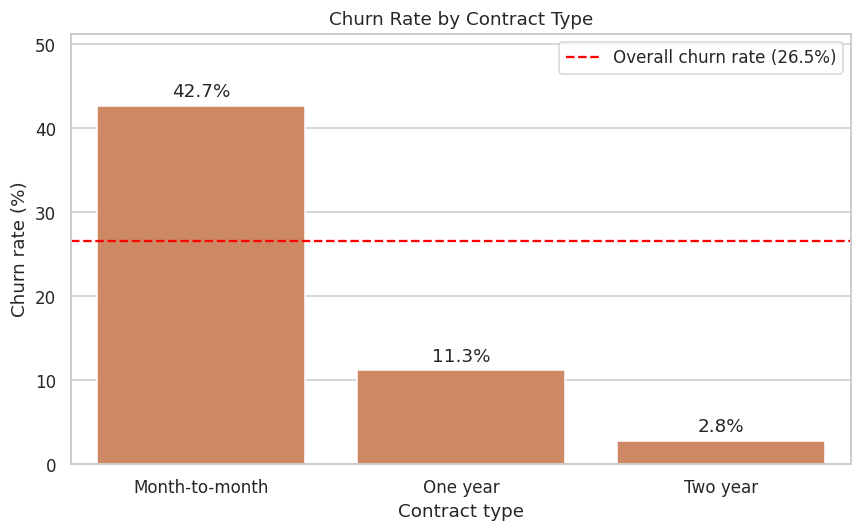

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=contract_churn, x="Contract", y="churn_rate", color="#DD8452", ax=ax)
for c in ax.containers:
    ax.bar_label(c, fmt="%.1f%%", padding=3)

ax.axhline(churn_rate, color="red", linestyle="--", label=f"Overall churn rate ({churn_rate:.1f}%)")
ax.set_title("Churn Rate by Contract Type")
ax.set_xlabel("Contract type")
ax.set_ylabel("Churn rate (%)")
ax.set_ylim(0, contract_churn["churn_rate"].max() * 1.2)
ax.legend()
plt.tight_layout()
plt.savefig("churn_by_contract.png", dpi=150, bbox_inches="tight")
plt.show()

- **What this shows:** Month-to-month customers churn at **42.7%**, versus **11.3%** for one-year and **2.8%** for two-year contracts.
- **Business meaning:** Contract length is a **strong** driver of churn: month-to-month customers churn about 15 times more than two-year customers and account for roughly 89% of all churned customers (1,655 of 1,869).
- Moving month-to-month customers onto longer contracts, for example with a discount, is the clearest retention lever.

## Business Question 3: Billing & Payment Factors
### Step 9: Churn rate by payment method
Group customers by payment method (Electronic check, Mailed check, Bank transfer, Credit card) and calculate the number of customers, number churned and churn rate for each.

In [ ]:
payment_churn = df.groupby("PaymentMethod")["churn_flag"].agg(
    customers="count", churned="sum", churn_rate="mean").reset_index()
payment_churn["churn_rate"] = (payment_churn["churn_rate"] * 100).round(2)
payment_churn = payment_churn.sort_values("churn_rate", ascending=False)
payment_churn

,PaymentMethod,customers,churned,churn_rate
2,Electronic check,2365,1071,45.29
3,Mailed check,1612,308,19.11
0,Bank transfer (automatic),1544,258,16.71
1,Credit card (automatic),1522,232,15.24


### Step 10: Chart 3, Churn rate by payment method
A horizontal bar chart of churn rate for each payment method, with the overall churn rate shown as a red dashed line for comparison.

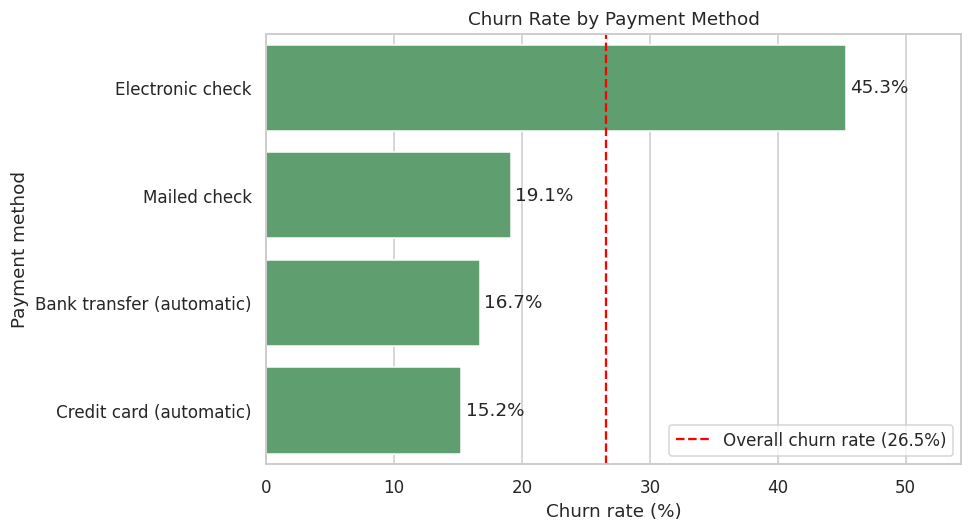

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=payment_churn, y="PaymentMethod", x="churn_rate", color="#55A868", ax=ax)
for c in ax.containers:
    ax.bar_label(c, fmt="%.1f%%", padding=3)

ax.axvline(churn_rate, color="red", linestyle="--", label=f"Overall churn rate ({churn_rate:.1f}%)")
ax.set_title("Churn Rate by Payment Method")
ax.set_xlabel("Churn rate (%)")
ax.set_ylabel("Payment method")
ax.set_xlim(0, payment_churn["churn_rate"].max() * 1.2)
ax.legend()
plt.tight_layout()
plt.savefig("churn_by_payment_method.png", dpi=150, bbox_inches="tight")
plt.show()

- **What this shows:** Electronic check customers churn the most (**45.3%**), while credit card (automatic) and bank transfer (automatic) customers churn the least (**15.2%** and **16.7%**). Mailed check sits in between at 19.1%.
- **Business meaning:** Electronic check is a clear warning flag: those customers churn about 3 times more than automatic payers, and they make up 57% of all churned customers (1,071 of 1,869).
- Encouraging automatic payment may help retention, and Step 11 checks whether this effect is separate from contract type.

### Step 11: Is the payment effect just a contract effect?
Some payment methods may be more common on month-to-month contracts. This table shows the churn rate for each payment method **within** each contract type, to check whether payment method matters on its own.

In [ ]:
pd.crosstab(df["PaymentMethod"], df["Contract"], values=df["churn_flag"], aggfunc="mean").mul(100).round(1)

Contract,Month-to-month,One year,Two year
PaymentMethod,,,
Bank transfer (automatic),34.1,9.7,3.4
Credit card (automatic),32.8,10.3,2.2
Electronic check,53.7,18.4,7.7
Mailed check,31.6,6.8,0.8


- **What this shows:** Within month-to-month contracts, electronic check customers still churn at **53.7%**, compared with **31.6% to 34.1%** for the other payment methods.
- **Business meaning:** Payment method **does** show a separate effect beyond contract type: electronic check has the highest churn within every contract length (53.7%, 18.4% and 7.7%).
- Retention efforts should target month-to-month customers who pay by electronic check, the highest-risk group.

### Step 12: Save the cleaned dataset


In [ ]:
df.to_csv("cleaned_telco_churn.csv", index=False)
print("Saved")

Saved


## Conclusion: The Churn Story
1. **Baseline:** 26.5% of customers churn overall (1,869 of 7,043).
2. **Contracts:** month-to-month customers churn at 42.7%, far higher than two-year customers (2.8%).
3. **Payment:** electronic check customers churn the most (45.3%), while credit card (automatic) customers churn the least (15.2%).

**Recommendation:** Focus retention on month-to-month customers using discounts for one- or two-year contracts, and encourage electronic check customers to switch to automatic payment (bank transfer or credit card) to reduce churn.